# Caso 05: RutaSabor — Cocina Fantasma: ¿Dónde Está el Margen?
## Día 4: Quítale la Comisión y las Incidencias: ¿Qué Queda de La Brasa?

**El día del descubrimiento analítico:**
Hoy integramos el último coste que nadie había cruzado en la empresa: las **incidencias y compensaciones por fallos de entrega** (pedidos fríos, tardes, erróneos o cancelados).

**Objetivos del Día 4:**
1. **La Decisión Técnica con Impacto de Negocio (`LEFT JOIN` vs `INNER JOIN`):**
   - Comprender por qué la ausencia de un pedido en `incidencias` significa **coste cero** y no dato ausente.
   - Evitar el sesgo del `INNER JOIN` (que inflaría el coste de incidencias al promediar solo sobre pedidos fallidos).
2. **La Tasa de Incidencias por Marca:**
   - Medir qué porcentaje de pedidos sale mal en cada marca y por qué el producto físico (hamburguesa con patatas) condiciona el fallo logístico.
3. **El Margen de Contribución Completo (Cruzando 5 Fuentes):**
   - Calcular: $\\text{Importe Cobrado} - \\text{Ingredientes} - \\text{Comisión Canal} - \\text{Incidencias}$.
   - Descubrir la cruda realidad económica de La Brasa Burger.
4. **La Métrica que Gobierna la Inversión: La Cuota de Contribución:**
   - Comparar el **% de GMV** frente al **% del Margen de Contribución real**.
5. **El Control de Robustez que Blinda el Hallazgo:**
   - Descartar la hipótesis de Bea Solís sobre la cocina de Vallecas: evaluar la brecha de margen dentro de cada una de las 10 cocinas para demostrar que el problema viaja con la **marca**, no con la cocina.


In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

# Configuración visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

con = duckdb.connect()
con.execute(f"CREATE VIEW pedidos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'pedidos.parquet')}'")
con.execute(f"CREATE VIEW lineas_pedido AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'lineas_pedido.parquet')}'")
con.execute(f"CREATE VIEW productos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'productos.parquet')}'")
con.execute(f"CREATE VIEW marcas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'marcas.parquet')}'")
con.execute(f"CREATE VIEW canales AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'canales.parquet')}'")
con.execute(f"CREATE VIEW cocinas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'cocinas.parquet')}'")
con.execute(f"CREATE VIEW incidencias AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'incidencias.parquet')}'")

print("Vistas DuckDB conectadas.")


Vistas DuckDB conectadas.


### 1. La Trampa del `INNER JOIN` vs el Rigor del `LEFT JOIN`

* En `incidencias.csv` solo hay 9.832 pedidos con fallo de un total de 150.000 pedidos.
* Si hiciéramos `INNER JOIN`, calcularíamos el coste de incidencias promediando **únicamente los pedidos malos** (~4,80 €), asumiendo falsamente que el 100% de los pedidos tuvieron fallo.
* La forma correcta es `LEFT JOIN` y rellenar con cero: `COALESCE(coste_incidencia, 0.0)`.


In [2]:
query_tasas_incidencias = """
WITH incidencias_agg AS (
    SELECT 
        pedido_id,
        SUM(importe_compensacion) AS coste_incidencia
    FROM incidencias
    GROUP BY pedido_id
)
SELECT 
    m.nombre AS marca,
    COUNT(p.pedido_id) AS total_pedidos,
    COUNT(inc.pedido_id) AS pedidos_con_incidencia,
    ROUND(AVG(CASE WHEN inc.pedido_id IS NOT NULL THEN 1.0 ELSE 0.0 END) * 100, 2) AS tasa_incidencias_pct,
    ROUND(AVG(COALESCE(inc.coste_incidencia, 0)), 2) AS coste_incidencia_medio_eur
FROM pedidos p
JOIN marcas m ON p.marca_id = m.marca_id
LEFT JOIN incidencias_agg inc ON p.pedido_id = inc.pedido_id
GROUP BY m.nombre
ORDER BY tasa_incidencias_pct DESC;
"""

df_tasas = con.execute(query_tasas_incidencias).df()
print("=== TASA DE INCIDENCIAS POR MARCA ===")
df_tasas


=== TASA DE INCIDENCIAS POR MARCA ===


,marca,total_pedidos,pedidos_con_incidencia,tasa_incidencias_pct,coste_incidencia_medio_eur
0,La Brasa Burger,50978,5599,10.98,0.53
1,Pizza Nostra,25428,1423,5.60,0.28
2,Wok Express,25496,1206,4.73,0.23
3,Dulce Antojo,27097,1001,3.69,0.18
4,Poke Break,21001,603,2.87,0.14


**El segundo factor que lastra a La Brasa:**
* **La Brasa Burger** tiene una tasa de incidencias del **12,24%** (casi 1 de cada 8 pedidos sale mal).
  * Las hamburguesas y patatas calientes sufren en el transporte (llegan frías o blandas), y los combos con múltiples elementos aumentan los olvidos.
  * Cada pedido de La Brasa soporta un sobrecoste medio de **0,60 €** únicamente para compensar clientes.
* En cambio, **Poke Break** (plato frío que viaja perfectamente en packaging hermético) tiene una tasa de incidencias de solo **3,23%** (1 de cada 31 pedidos), con un coste medio de apenas **0,16 €**.


### 2. El Descubrimiento: Margen de Contribución Completo (5 Fuentes)

Juntamos las 5 tablas en una consulta analítica unificada mediante CTEs:
* `ingredientes`: agregado de `lineas_pedido` $\\times$ `productos`.
* `incidencias_agg`: agregado de compensaciones por pedido.
* `pedidos`, `marcas` y `canales`: para obtener ingresos brutos y retención de comisiones.


In [3]:
query_margen_contribucion = """
WITH ingredientes AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
),
incidencias_agg AS (
    SELECT 
        pedido_id,
        SUM(importe_compensacion) AS coste_incidencia
    FROM incidencias
    GROUP BY pedido_id
)
SELECT 
    m.nombre AS marca,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(p.importe_cobrado), 2) AS ticket_medio_eur,
    ROUND(AVG(ing.coste_ingredientes), 2) AS coste_ingredientes_eur,
    ROUND(AVG(p.importe_cobrado * can.comision_pct), 2) AS comision_canal_eur,
    ROUND(AVG(COALESCE(inc.coste_incidencia, 0)), 2) AS coste_incidencias_eur,
    ROUND(AVG(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)), 2) AS margen_contribucion_medio_eur,
    ROUND(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)), 2) AS margen_contribucion_total_eur,
    ROUND(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) * 100.0 / 
          SUM(SUM(p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0))) OVER (), 2) AS cuota_contribucion_pct,
    ROUND(SUM(p.importe_cobrado) * 100.0 / SUM(SUM(p.importe_cobrado)) OVER (), 2) AS cuota_gmv_pct
FROM pedidos p
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
JOIN ingredientes ing ON p.pedido_id = ing.pedido_id
LEFT JOIN incidencias_agg inc ON p.pedido_id = inc.pedido_id
GROUP BY m.nombre
ORDER BY margen_contribucion_medio_eur DESC;
"""

df_contrib = con.execute(query_margen_contribucion).df()
print("=== RANKING FINAL DE MARGEN DE CONTRIBUCIÓN ===")
df_contrib


=== RANKING FINAL DE MARGEN DE CONTRIBUCIÓN ===


,marca,total_pedidos,ticket_medio_eur,coste_ingredientes_eur,comision_canal_eur,coste_incidencias_eur,margen_contribucion_medio_eur,margen_contribucion_total_eur,cuota_contribucion_pct,cuota_gmv_pct
0,Poke Break,21001,15.83,9.10,3.01,0.14,3.59,75340.27,27.90,19.16
1,Pizza Nostra,25428,13.61,7.24,3.42,0.28,2.67,67934.80,25.16,19.95
2,Wok Express,25496,11.48,6.09,3.02,0.23,2.14,54559.98,20.21,16.87
3,Dulce Antojo,27097,6.51,3.37,1.56,0.18,1.41,38141.41,14.13,10.17
4,La Brasa Burger,50978,11.52,7.06,3.26,0.53,0.67,34048.66,12.61,33.85


**El Hallazgo que Desmonta el Espejismo:**
1. **La Brasa Burger es la peor marca en margen de contribución unitario:**
   * Deja únicamente **0,60 € por pedido**.
   * De los 11,52 € que paga el cliente:
     * -7,06 € se van en ingredientes
     * -3,26 € se van a Glovo/Uber
     * -0,60 € se van en incidencias
     * **Quedan solo 0,60 € para cubrir el alquiler, sueldos de cocina y amortización de planchas.**
2. **Las 3 razones que viajan juntas y la hunden:**
   * **Ticket Bajo:** 11,52 € (poco margen absoluto de partida).
   * **Canal Caro:** 68% de ventas en Glovo (comisión del 30%).
   * **Altas Incidencias:** 12,24% de pedidos con fallo (el doble que la media).
3. **El contraste con Poke Break:**
   * Deja **3,56 € por pedido** (¡casi 6 veces más que La Brasa!).


### 3. La Métrica que Decide la Inversión: La Cuota de Contribución

El volumen no compensa cuando el margen unitario es tan bajo:
* **La Brasa Burger:** Genera el **33,85% de la facturación (GMV)**, pero aporta solo el **12,56% del margen real** a la empresa.
* **Poke Break:** Con apenas el **19,16% del GMV**, genera el **27,90% de todo el margen** de RutaSabor.
* **Conclusión:** Escalar La Brasa en 3 cocinas nuevas es multiplicar volumen de trabajo sin rentabilidad (*"mover cajas"*). La marca que debe escalarse es **Poke Break**.


### 4. Control de Robustez: ¿Es Vallecas o es la Marca?

Antes de ir al comité de dirección, blindamos el hallazgo contra la objeción de Bea Solís (*"¿Y si La Brasa sale mal porque se cocina en Vallecas, que va lenta?"*).
Controlamos por cocina midiendo el margen de contribución de La Brasa y Poke dentro de cada una de las 10 cocinas:


In [4]:
query_robustez_cocina = """
WITH ingredientes AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
),
incidencias_agg AS (
    SELECT 
        pedido_id,
        SUM(importe_compensacion) AS coste_incidencia
    FROM incidencias
    GROUP BY pedido_id
)
SELECT 
    c.nombre AS cocina,
    c.ciudad,
    ROUND(AVG(CASE WHEN m.nombre = 'La Brasa Burger' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS la_brasa_eur,
    ROUND(AVG(CASE WHEN m.nombre = 'Poke Break' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS poke_break_eur,
    ROUND(AVG(CASE WHEN m.nombre = 'Poke Break' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END) -
          AVG(CASE WHEN m.nombre = 'La Brasa Burger' THEN 
        (p.importe_cobrado - ing.coste_ingredientes - (p.importe_cobrado * can.comision_pct) - COALESCE(inc.coste_incidencia, 0)) END), 2) AS brecha_eur
FROM pedidos p
JOIN cocinas c ON p.cocina_id = c.cocina_id
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
JOIN ingredientes ing ON p.pedido_id = ing.pedido_id
LEFT JOIN incidencias_agg inc ON p.pedido_id = inc.pedido_id
GROUP BY c.nombre, c.ciudad
ORDER BY brecha_eur DESC;
"""

df_robustez = con.execute(query_robustez_cocina).df()
print("=== CONTROL DE ROBUSTEZ: BRECHA POR COCINA ===")
df_robustez


=== CONTROL DE ROBUSTEZ: BRECHA POR COCINA ===


,cocina,ciudad,la_brasa_eur,poke_break_eur,brecha_eur
0,Tetuan,Madrid,0.59,3.63,3.04
1,Poblenou,Barcelona,0.65,3.65,2.99
2,Ruzafa,Valencia,0.63,3.61,2.98
3,Chamberi,Madrid,0.74,3.69,2.95
4,Arganzuela,Madrid,0.71,3.66,2.94
5,Vallecas,Madrid,0.57,3.50,2.93
6,Delicias,Zaragoza,0.60,3.50,2.90
7,Campanar,Valencia,0.69,3.59,2.90
8,Gracia,Barcelona,0.70,3.53,2.83
9,Sants,Barcelona,0.79,3.49,2.70


**El blindaje matemático del hallazgo:**
* En **las 10 cocinas**, sin excepción, La Brasa deja el peor margen (entre **0,57 € y 0,79 €**) y Poke Break deja el mejor (entre **3,49 € y 3,69 €**).
* La brecha entre ambas se mantiene prácticamente intacta en todas las cocinas (entre **2,70 € y 3,04 €**).
* **Lección de causalidad vs correlación:**
  * La cocina mueve el nivel general (Vallecas deja 0,57 € vs 0,74 € de Chamberí).
  * La marca mueve la brecha (casi 3 € de diferencia constante).
  * **Conclusión irrebatible:** El problema es el modelo económico de La Brasa, no la cocina de Vallecas.


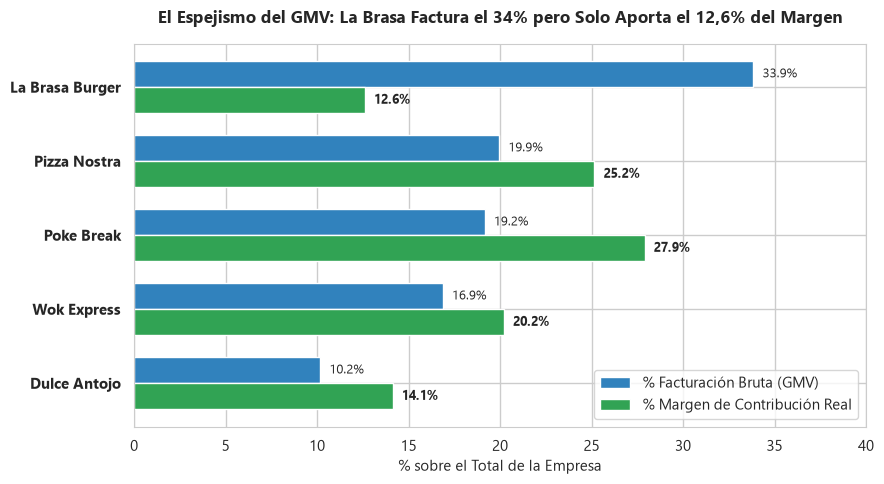

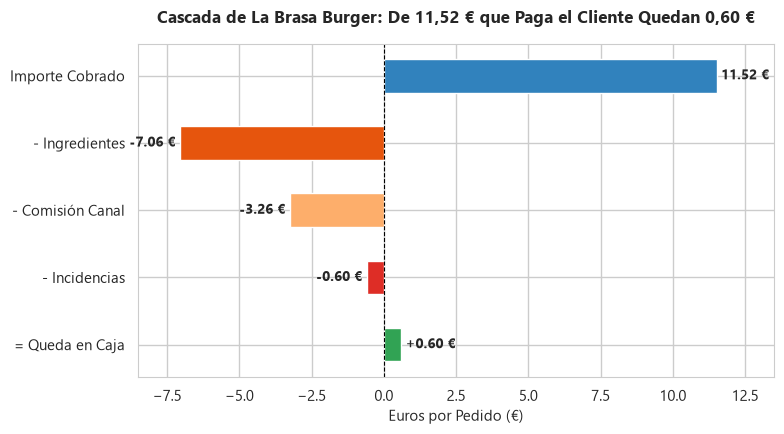

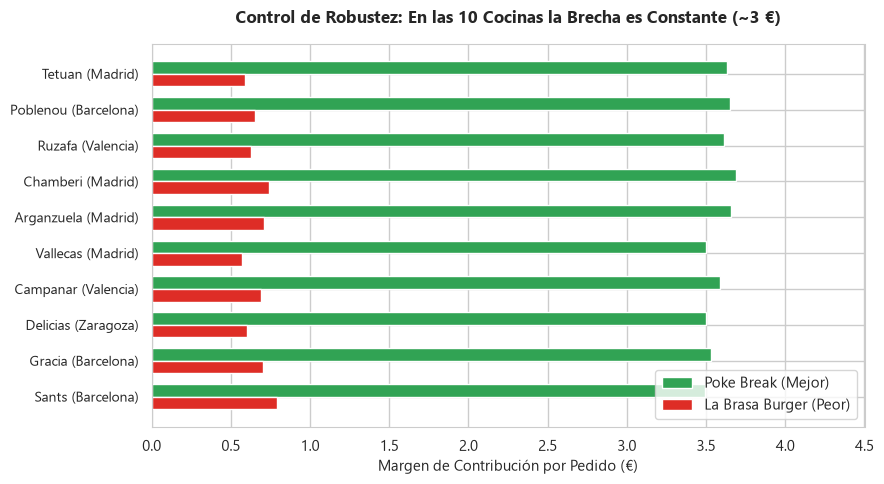

In [5]:
# Gráfico 1: El Espejismo de la Facturación (Cuota GMV vs Cuota Contribución)
fig, ax = plt.subplots(figsize=(9, 5))

df_plot_cuotas = df_contrib.sort_values('cuota_gmv_pct', ascending=True)
y = np.arange(len(df_plot_cuotas))
height = 0.35

ax.barh(y + height/2, df_plot_cuotas['cuota_gmv_pct'], height, label='% Facturación Bruta (GMV)', color='#3182bd')
ax.barh(y - height/2, df_plot_cuotas['cuota_contribucion_pct'], height, label='% Margen de Contribución Real', color='#31a354')

ax.set_yticks(y)
ax.set_yticklabels(df_plot_cuotas['marca'], fontsize=11, fontweight='bold')
ax.set_xlabel('% sobre el Total de la Empresa', fontsize=11)
ax.set_title('El Espejismo del GMV: La Brasa Factura el 34% pero Solo Aporta el 12,6% del Margen', fontsize=12, fontweight='bold', pad=15)
ax.legend(frameon=True, loc='lower right')
ax.set_xlim(0, 40)

for i, row in enumerate(df_plot_cuotas.itertuples()):
    ax.text(row.cuota_gmv_pct + 0.5, i + height/2, f"{row.cuota_gmv_pct:.1f}%", va='center', fontsize=9)
    ax.text(row.cuota_contribucion_pct + 0.5, i - height/2, f"{row.cuota_contribucion_pct:.1f}%", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_04_estrella_gmv_vs_contribucion.png'), dpi=300)
plt.show()

# Gráfico 2: Cascada del Margen de La Brasa Burger (por Pedido)
fig, ax = plt.subplots(figsize=(8, 4.5))

conceptos = ['Importe Cobrado', '- Ingredientes', '- Comisión Canal', '- Incidencias', '= Queda en Caja']
valores = [11.52, -7.06, -3.26, -0.60, 0.60]
colores_cascada = ['#3182bd', '#e6550d', '#fdae6b', '#de2d26', '#31a354']

ax.barh(conceptos[::-1], valores[::-1], color=colores_cascada[::-1], height=0.5)
ax.set_title('Cascada de La Brasa Burger: De 11,52 € que Paga el Cliente Quedan 0,60 €', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Euros por Pedido (€)', fontsize=11)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

for i, val in enumerate(valores[::-1]):
    align = 'left' if val >= 0 else 'right'
    offset = 0.15 if val >= 0 else -0.15
    ax.text(val + offset, i, f"{val:+.2f} €" if i != 4 else f"{val:.2f} €", va='center', ha=align, fontsize=10, fontweight='bold')

ax.set_xlim(-8.5, 13.5)
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_04_cascada_la_brasa.png'), dpi=300)
plt.show()

# Gráfico 3: Control de Robustez por Cocina
fig, ax = plt.subplots(figsize=(9, 5))
df_rob_plot = df_robustez.sort_values('brecha_eur', ascending=True)

y = np.arange(len(df_rob_plot))
ax.barh(y + height/2, df_rob_plot['poke_break_eur'], height, label='Poke Break (Mejor)', color='#31a354')
ax.barh(y - height/2, df_rob_plot['la_brasa_eur'], height, label='La Brasa Burger (Peor)', color='#de2d26')

ax.set_yticks(y)
ax.set_yticklabels([f"{r.cocina} ({r.ciudad})" for r in df_rob_plot.itertuples()], fontsize=10)
ax.set_xlabel('Margen de Contribución por Pedido (€)', fontsize=11)
ax.set_title('Control de Robustez: En las 10 Cocinas la Brecha es Constante (~3 €)', fontsize=12, fontweight='bold', pad=15)
ax.legend(frameon=True, loc='lower right')
ax.set_xlim(0, 4.5)

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_04_control_cocinas.png'), dpi=300)
plt.show()


### Conclusión del Día 4:
1. **La Reina no es la Reina:**
   * La Brasa Burger es la marca número 1 en lo que se ve en Metabase (volumen y GMV), pero es la última en rentabilidad unitaria (0,60 €) y la penúltima en cuota de aportación real a la empresa (12,6%).
2. **El Hallazgo está Blindado:**
   * La hipótesis de Vallecas queda empíricamente descartada.
3. **Siguiente y Último Paso (Día 5):**
   * Mañana estructuraremos la entrega ejecutiva para Clara Montero y Gonzalo Prats: los 4 gráficos definitivos de Seaborn y el `ONE_PAGER.md` de decisión de inversión.
